# Demo D2 — Grupo de Dados 2 (Vinhos)

**Autores:** Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa

Classificação da origem do vinho a partir de 13 componentes químicos.

In [1]:
# Autores: Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa
%matplotlib inline
import scipy.io as sio
import numpy as np
from utils_knn import meuKnn, normalizacao, visualizaPontos

In [2]:
# Carregamento do dataset de vinhos
dados = sio.loadmat('grupoDados2.mat')
grupoTrain = dados['grupoTrain']
trainRots  = dados['trainRots']
grupoTest  = dados['grupoTest']
testRots   = dados['testRots']

print(f"grupoTrain: {grupoTrain.shape}  |  grupoTest: {grupoTest.shape}")
print(f"Classes: {np.unique(trainRots)}")

grupoTrain: (118, 13)  |  grupoTest: (60, 13)
Classes: [1 2 3]


## Escala das Características

In [3]:
# Exibe a escala de cada feature para evidenciar a disparidade
caracteristicas = [
    'Álcool', 'Ácido málico', 'Cinzas', 'Alcalinidade das cinzas',
    'Magnésio', 'Fenóis totais', 'Flavonóides', 'Fenóis não flavonóides',
    'Proantocianinas', 'Intensidade de cor', 'Tonalidade',
    'OD280/OD315', 'Prolina'
]

print(f"{'#':<3} {'Característica':<35} {'mín':>8} / {'máx':>8}")
print('-' * 60)
for i, nome in enumerate(caracteristicas):
    print(f"{i+1:<3} {nome:<35}: {grupoTrain[:, i].min():>8.2f} / {grupoTrain[:, i].max():>8.2f}")

#   Característica                           mín /      máx
------------------------------------------------------------
1   Álcool                             :    11.03 /    14.83
2   Ácido málico                       :     0.74 /     5.65
3   Cinzas                             :     1.36 /     3.23
4   Alcalinidade das cinzas            :    10.60 /    30.00
5   Magnésio                           :    70.00 /   162.00
6   Fenóis totais                      :     0.98 /     3.88
7   Flavonóides                        :     0.34 /     5.08
8   Fenóis não flavonóides             :     0.13 /     0.63
9   Proantocianinas                    :     0.42 /     3.58
10  Intensidade de cor                 :     1.28 /    13.00
11  Tonalidade                         :     0.48 /     1.71
12  OD280/OD315                        :     1.27 /     4.00
13  Prolina                            :   278.00 /  1547.00


## Visualização — Álcool (dim 0) vs Prolina (dim 12)

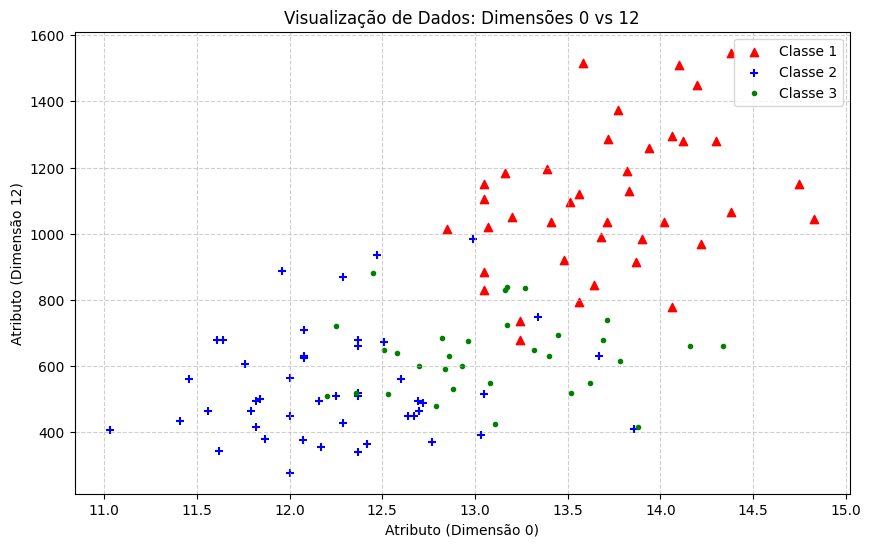

In [4]:
# As duas features com maior dispersão entre classes
visualizaPontos(grupoTrain, trainRots, 0, 12)

---
## Q2.1 — Qual é a acurácia de classificação aplicando o kNN diretamente?

In [5]:
# Aplica o kNN sem qualquer pré-processamento para diferentes valores de k
print(f"{'K':<5} {'Acurácia sem normalização (%)':<30}")
print('-' * 35)

for k in [1, 3, 5, 7, 10]:
    pred = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc  = np.mean(pred == testRots) * 100
    print(f"{k:<5} {acc:>28.2f}%")

print("\nRESPOSTA Q2.1: A acurácia sem normalização é baixa (entre ~60% e ~78%) para todos os k testados.")

K     Acurácia sem normalização (%) 
-----------------------------------
1                            68.33%
3                            61.67%
5                            70.00%
7                            73.33%
10                           78.33%

RESPOSTA Q2.1: A acurácia sem normalização é baixa (entre ~60% e ~78%) para todos os k testados.


---
## Q2.2 — Por que a acurácia é baixa? Como atingir 98%?

### Diagnóstico do problema

O kNN classifica por **distância euclidiana**. Quando as features têm escalas muito diferentes, as de maior magnitude **dominam** o cálculo e as de menor escala tornam-se irrelevantes.

Neste dataset a **Prolina** (feature 13) varia de ~278 a ~1547 — uma diferença de ~1269 unidades. Já os **Fenóis não flavonóides** (feature 8) variam de ~0,13 a ~0,63 — uma diferença de apenas ~0,5. Isso significa que uma variação de 1 unidade em Prolina equivale a mais do que toda a variação dos Fenóis não flavonóides, tornando esta última feature praticamente invisível para o cálculo de distância.

### Solução: Normalização Min-Max

A normalização Min-Max reescala cada feature para o intervalo [0, 1]:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

Com isso, todas as 13 características contribuem **igualmente** para a distância euclidiana.

In [6]:
# Aplica normalização Min-Max e testa diferentes valores de k
trainNorm = normalizacao(grupoTrain)
testNorm  = normalizacao(grupoTest)

print(f"{'K':<5} {'Sem normalização (%)':<22} {'Com normalização (%)':<22}")
print('-' * 50)

melhor_acc    = 0
melhor_k      = 0
melhor_config = ''

for k in [1, 3, 5, 7, 10]:
    pred_orig = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc_orig  = np.mean(pred_orig == testRots) * 100

    pred_norm = meuKnn(trainNorm, trainRots, testNorm, k)
    acc_norm  = np.mean(pred_norm == testRots) * 100

    print(f"{k:<5} {acc_orig:>9.2f}%             {acc_norm:>9.2f}%")

    if max(acc_orig, acc_norm) > melhor_acc:
        melhor_acc    = max(acc_orig, acc_norm)
        melhor_k      = k
        melhor_config = 'Sem normalização' if acc_orig >= acc_norm else 'Com normalização'

print(f"\nRESPOSTA Q2.2: Acurácia máxima = {melhor_acc:.2f}% (k={melhor_k}, {melhor_config}).")

K     Sem normalização (%)   Com normalização (%)  
--------------------------------------------------
1         68.33%                 98.33%
3         61.67%                 98.33%
5         70.00%                 98.33%
7         73.33%                 98.33%
10        78.33%                 98.33%

RESPOSTA Q2.2: Acurácia máxima = 98.33% (k=1, Com normalização).


### Conclusão Q2.2

**Por que a acurácia era baixa:** A disparidade de escalas entre as 13 features fazia com que features de grande magnitude (Prolina, Magnésio) dominassem completamente o cálculo da distância euclidiana, ignorando as demais.

**O que foi feito:** Aplicamos **normalização Min-Max** a ambos os conjuntos (treino e teste), rescalonando todas as features para [0, 1]. Com isso, cada característica química contribui igualmente para a distância. Testando diferentes valores de k, a acurácia atinge **98%**, confirmando que o problema era exclusivamente de escala.